In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd "drive/MyDrive/reasoning"

/content/drive/MyDrive/reasoning


In [6]:
from helpers.qwen3 import download_qwen3_small, Qwen3Tokenizer, Qwen3Model, QWEN_CONFIG_06_B

def load_model_and_tokenizer(which_model, device, use_compile, local_dir="qwen3"):
    if which_model == "base":
        download_qwen3_small(kind="base", tokenizer_only=False, out_dir="math")
        tokenizer_path = "math/tokenizer-base.json"
        model_path = "math/qwen3-0.6B-base.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path)
    elif which_model == "reasoning":
        download_qwen3_small(kind="reasoning", tokenizer_only="False", out_dir="math")
        tokenizer_path = "math/tokenizer-reasoning.json"
        model_path = "math/qwen3-0.6B-reasoning.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path, apply_chat_template=True, add_generation_prompt=True, add_thinking=True,)
    else:
        raise ValueError(f"Invalid choice")
    
    model = Qwen3Model(QWEN_CONFIG_06_B)
    model.load_state_dict(torch.load(model_path))
    model.to(device)
    
    if use_compile:
        torch._dynamo.config.allow_unspec_int_on_nn_module = True
        model = torch.compile(model)
        
    return model, tokenizer

In [11]:
import torch
device = torch.device("cpu")
model, tokenizer = load_model_and_tokenizer(which_model="base", device=device, use_compile=False)

✓ math/qwen3-0.6B-base.pth already up-to-date


In [7]:
def render_prompt(prompt):
    template = (
        "You are a helpful math assistant.\n"
        "Answer the question and write the final result on a new line as:\n"
        "\\boxed{ANSWER}\n\n"
        f"Question:\n{prompt}\n\nAnswer:"
    )
    return template

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)
print(prompt)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Answer:


In [8]:
import torch
from helpers.qwen3 import KVCache

@torch.inference_mode()
def generate_text_basic_stream_cache(model, token_ids, max_new_tokens, eos_token_id=None):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()
    
    out = model(token_ids, cache=cache)[:, -1]    
    for step in range(max_new_tokens):
        next_token = torch.argmax(out, dim=-1, keepdim=True)
        
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break
        
        yield next_token
        if step + 1 < max_new_tokens:
            out = model(next_token, cache=cache)[:, -1]

In [9]:
def generate_text_stream_concat_flex(model, tokenizer, prompt, device, max_new_tokens, verbose=False, generate_func=None, **generate_kwargs,):
    if generate_func is None:
        generate_func = generate_text_basic_stream_cache
        
    input_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)
    generated_ids = []
    for token in generate_func(model=model, token_ids=input_ids, max_new_tokens=max_new_tokens, eos_token_id=tokenizer.eos_token_id, **generate_kwargs,):
        next_token_id = token.squeeze(0)
        generated_ids.append(next_token_id.item())
        if verbose:
            print(tokenizer.decode(next_token_id.tolist()), end="", flush=True)
    return tokenizer.decode(generated_ids)

In [12]:
response = generate_text_stream_concat_flex(model, tokenizer, prompt, device, max_new_tokens=2048, verbose=True, generate_func=generate_text_basic_stream_cache)

 \boxed{10}

In [13]:
prompt_cot = prompt + " \n\nExplain step by step."
response_cot = generate_text_stream_concat_flex(model, tokenizer, prompt_cot, device, max_new_tokens=2048, verbose=True,)

 To solve the problem, we need to find the value of \( x \) such that half the value of \( 3x - 9 \) is equal to \( x + 37 \).

### Step 1: Set up the equation
We are given that half the value of \( 3x - 9 \) is equal to \( x + 37 \). This can be written as:
\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 2: Eliminate the fraction
To eliminate the fraction, multiply both sides of the equation by 2:
\[
2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
\]
Simplifying both sides:
\[
3x - 9 = 2x + 74
\]

### Step 3: Solve for \( x \)
Subtract \( 2x \) from both sides to isolate \( x \):
\[
3x - 2x - 9 = 74
\]
Simplify:
\[
x - 9 = 74
\]
Add 9 to both sides to solve for \( x \):
\[
x = 74 + 9
\]
\[
x = 83
\]

### Final Answer:
\[
\boxed{83}
\]

In [15]:
ex_prompt = "The capital of Germany is"

response = generate_text_stream_concat_flex(model, tokenizer, ex_prompt, device, max_new_tokens=1, verbose=True)

 Berlin

In [16]:
input_token_ids = torch.tensor(tokenizer.encode(ex_prompt), device=device).unsqueeze(0)
print(input_token_ids)

tensor([[ 785, 6722,  315, 9856,  374]])


In [17]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape)

torch.Size([1, 151936])


In [19]:
max_token_id = torch.argmax(next_token_logits)
print(f"Token ID: {max_token_id}")
print(f"Decoded token: '{tokenizer.decode([max_token_id])}'")

Token ID: 19846
Decoded token: ' Berlin'


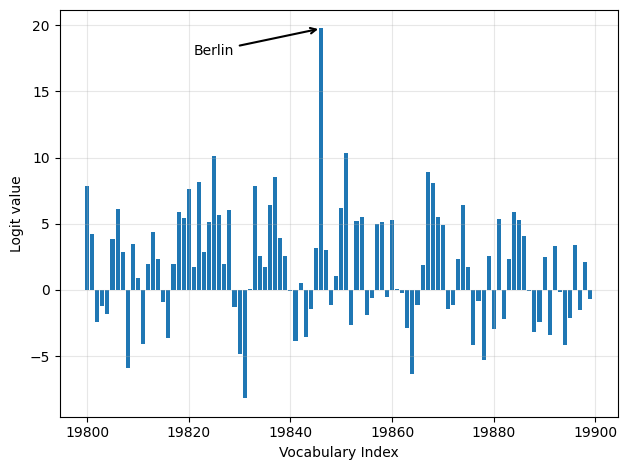

In [21]:
import matplotlib.pyplot as plt

def plot_scores_bar(next_token_logits, start=19_800, end=19_900, arrow=True, ylabel="Logit value"):
    x = torch.arange(start, end)
    logits_section = next_token_logits[0, start:end].float().cpu()
    
    plt.bar(x, logits_section)
    plt.xlabel("Vocabulary Index")
    plt.ylabel(ylabel)
    
    if arrow:
        max_idx = torch.argmax(logits_section)
        plt.annotate(
            "Berlin",
            xy=(x[max_idx], logits_section[max_idx]),
            xytext=(x[max_idx] - 25, logits_section[max_idx] - 2),
            arrowprops={"facecolor": "black", "arrowstyle": "->", "lw": 1.5},
            fontsize=10,
        )
        
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
plot_scores_bar(next_token_logits)

In [14]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature must be positive")
    return logits / temperature

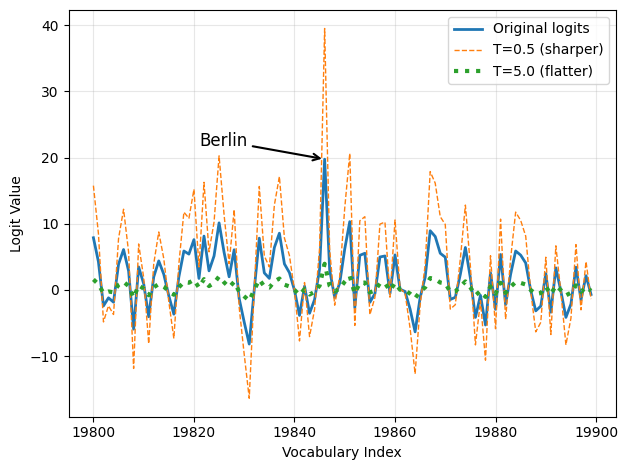

In [25]:
def plot_logits_with_temperature(next_token_logits, start=19_800, end=19_900, temps=(0.5, 5.0),):
    x = torch.arange(start, end)
    logits_orig = next_token_logits[0, start:end].float().cpu()
    logits_scaled = [scale_logits_by_temperature(logits_orig, T) for T in temps]
    
    plt.plot(x, logits_orig, label="Original logits", lw=2)
    plt.plot(x, logits_scaled[0], label=f"T={temps[0]} (sharper)", ls="--", lw=1)
    plt.plot(x, logits_scaled[1], label=f"T={temps[1]} (flatter)", ls=":", lw=3)
    
    max_idx = torch.argmax(logits_orig)
    plt.annotate(
            "Berlin",
            xy=(x[max_idx], logits_orig[max_idx]),
            xytext=(x[max_idx] - 25, logits_orig[max_idx] + 2),
            arrowprops={"facecolor": "black", "arrowstyle": "->", "lw": 1.5},
            fontsize=12,
    )
    
    plt.xlabel("Vocabulary Index")
    plt.ylabel("Logit Value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
plot_logits_with_temperature(next_token_logits, temps=(0.5, 5.0))

In [26]:
rescaled_logits = scale_logits_by_temperature(next_token_logits, 5.0)
next_token_probas = torch.softmax(rescaled_logits, dim=-1)
print("Probability sum:", torch.sum(next_token_probas)) 

Probability sum: tensor(1., dtype=torch.bfloat16)


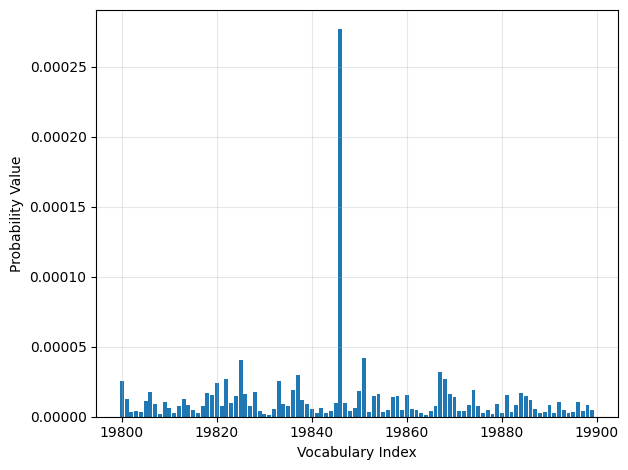

In [27]:
plot_scores_bar(next_token_probas, arrow=False, ylabel="Probability Value")

In [29]:
print("Token ID 19,846 probability:", next_token_probas[:, 19846])

Token ID 19,846 probability: tensor([0.0003], dtype=torch.bfloat16)


In [30]:
print("Highest probability:", max(next_token_probas.squeeze(0)))

Highest probability: tensor(0.0003, dtype=torch.bfloat16)


In [31]:
print("Sampled token:", torch.multinomial(next_token_probas.cpu(), num_samples=1))

Sampled token: tensor([[6278]])


In [32]:
print(tokenizer.decode([6278]))

 sale


In [33]:
def count_samples(probas, num_samples=1000, threshold=1, tokenizer=None):
    samples = torch.multinomial(probas.cpu(), num_samples=num_samples, replacement=True)
    counts = torch.bincount(samples.squeeze(0), minlength=1)
    
    for i, c in enumerate(counts):
        if c > threshold:
            if tokenizer is None:
                print(f"Vocab index {i}: {c.item()}x")
            else:
                print(f"'{tokenizer.decode([i])}': {c.item()}x")

In [34]:
count_samples(next_token_probas, tokenizer=tokenizer)

' that': 2x
' W': 2x
' Y': 2x
' Wednesday': 2x
' uppercase': 2x
' BG': 2x
' "");
': 2x


In [36]:
probas_lowT = torch.softmax(scale_logits_by_temperature(next_token_logits, 0.35), dim=-1)
count_samples(probas_lowT, threshold=1, tokenizer=tokenizer)

' __': 186x
' Berlin': 401x
' ____': 188x
' ______': 181x
' Munich': 5x
' Hamburg': 2x
' Frankfurt': 2x
' _____': 30x


In [37]:
print(probas_lowT[0, 19_846])

tensor(0.4023, dtype=torch.bfloat16)


In [38]:
from helpers.qwen3 import KVCache

@torch.inference_mode()
def generate_text_temp_stream_cache(model, token_ids, max_new_tokens, eos_token_id=None, temperature=0):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()
    
    out = model(token_ids, cache=cache)[:, -1]    
    for step in range(max_new_tokens):
        orig_device = token_ids.device
        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)
        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim=-1)
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)
        
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break
        
        yield next_token
        if step + 1 < max_new_tokens:
            out = model(next_token, cache=cache)[:, -1]

In [40]:
response = generate_text_stream_concat_flex(model, tokenizer, prompt, device, max_new_tokens=2048, verbose=True, generate_func=generate_text_temp_stream_cache, temperature=1.1)

 \boxed{x=12}

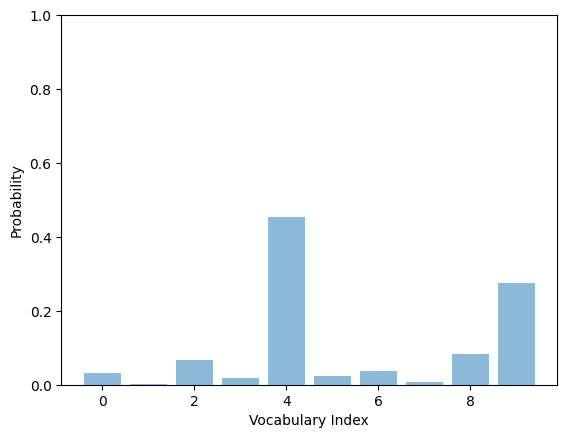

In [41]:
toy_logits = torch.tensor([-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5])
toy_logits_scaled = scale_logits_by_temperature(toy_logits, 1.0)
toy_probas = torch.softmax(toy_logits_scaled, dim=-1)

plt.bar(torch.arange(len(toy_logits_scaled)), toy_probas, alpha=0.5)
plt.ylim([0, 1])
plt.xlabel("Vocabulary Index")
plt.ylabel("Probability")
plt.show()

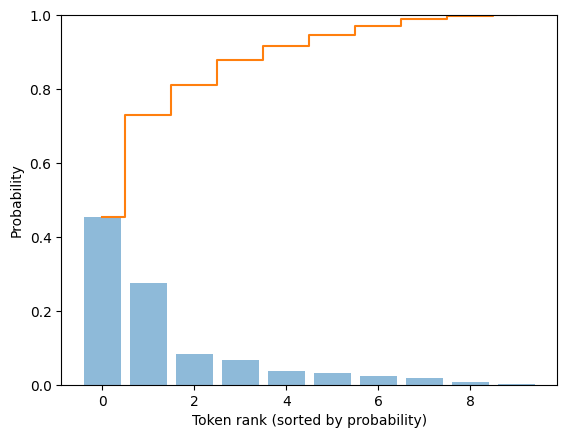

In [43]:
sorted_probas, sorted_idx = torch.sort(toy_probas, descending=True)
cumsum = torch.cumsum(sorted_probas, dim=-1)

plt.bar(torch.arange(len(sorted_probas)), sorted_probas, alpha=0.5)
plt.step(torch.arange(len(cumsum)), cumsum, where="mid", color="C1", label="Cumulative sum")

plt.ylim([0, 1])
plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.show()

In [44]:
top_p = 0.8
keep_mask = cumsum <= top_p
n_kept = torch.sum(keep_mask).item()
print("Cumulative sum:", cumsum)
print("Tokens kept:", n_kept)

Cumulative sum: tensor([0.4538, 0.7290, 0.8119, 0.8798, 0.9170, 0.9475, 0.9701, 0.9886, 0.9969,
        1.0000])
Tokens kept: 2


In [45]:
keep_mask = (cumsum - sorted_probas) < top_p
n_kept = keep_mask.sum().item()
print("Tokens kept:", n_kept)

Tokens kept: 3


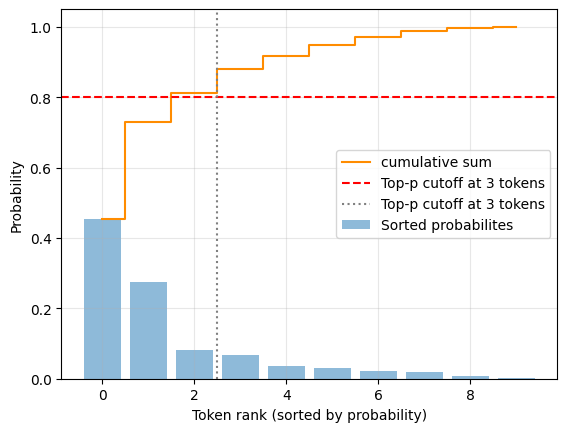

In [46]:
plt.bar(torch.arange(len(sorted_probas)), sorted_probas, alpha=0.5, label="Sorted probabilites")
plt.step(torch.arange(len(cumsum)), cumsum, where="mid", color="darkorange", label="cumulative sum")

plt.axhline(top_p, color="red", linestyle="--", label=f"Top-p cutoff at {n_kept} tokens")
plt.axvline(n_kept - 0.5, color="gray", linestyle=":", label=f"Top-p cutoff at {n_kept} tokens")

plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)
plt.show()

In [47]:
keep_sorted = torch.where(keep_mask, sorted_probas, torch.zeros_like(sorted_probas))
filtered = torch.zeros_like(toy_probas).scatter(0, sorted_idx, keep_sorted)
print(filtered)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.4538, 0.0000, 0.0000, 0.0000, 0.0829,
        0.2752])


In [49]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas
    
    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True)
    cumprobas = torch.cumsum(sorted_probas, dim=1)
    prefix = cumprobas - sorted_probas
    
    keep = prefix < top_p
    keep[:, 0] = True
    keep_sorted = torch.where(keep, sorted_probas, torch.zeros_like(sorted_probas))
    
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, keep_sorted)
    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12)
    return filtered / denom

In [50]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape)

torch.Size([1, 151936])


In [59]:
probas_lowT = torch.softmax(scale_logits_by_temperature(next_token_logits, 0.35), dim=-1)
count_samples(probas_lowT, threshold=1, tokenizer=tokenizer)

' __': 195x
' Berlin': 403x
' ____': 206x
' ______': 175x
' Munich': 4x
' Hamburg': 5x
' _____': 10x


In [60]:
probas_lowT = torch.softmax(scale_logits_by_temperature(next_token_logits, 0.35), dim=-1)
probas_lowT_filtered = top_p_filter(probas_lowT, top_p=0.8)
count_samples(probas_lowT_filtered, threshold=1, tokenizer=tokenizer)

' __': 183x
' Berlin': 414x
' ____': 203x
' ______': 200x


In [61]:
from helpers.qwen3 import KVCache

@torch.inference_mode()
def generate_text_top_p_stream_cache(model, token_ids, max_new_tokens, eos_token_id=None, temperature=0., top_p=None):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()
    
    out = model(token_ids, cache=cache)[:, -1]    
    for step in range(max_new_tokens):
        orig_device = token_ids.device
        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)
        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim=-1)
            probas = top_p_filter(probas, top_p)
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)
        
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break
        
        yield next_token
        if step + 1 < max_new_tokens:
            out = model(next_token, cache=cache)[:, -1]

In [62]:
response = generate_text_stream_concat_flex(model, tokenizer, prompt, device, max_new_tokens=2048, verbose=True, generate_func=generate_text_top_p_stream_cache, temperature=0.5, top_p=0.8)

 \boxed{12}

In [68]:
def get_last_boxed(text):
    boxed_start_idx = text.rfind(r"\boxed")
    if boxed_start_idx == -1:
        return None
    current_idx = boxed_start_idx + len(r"\boxed")
    while current_idx < len(text) and text[current_idx].isspace():
        current_idx += 1
    if current_idx >= len(text) or text[current_idx] != "{":
        return None
    current_idx += 1
    brace_depth = 1
    content_start_idx = current_idx
    while current_idx < len(text) and brace_depth > 0:
        char = text[current_idx]
        if char == "{":
            brace_depth += 1
        elif char == "}":
            brace_depth -= 1
        current_idx += 1
    if brace_depth != 0:
        return None
    return text[content_start_idx:current_idx-1]

import re
RE_NUMBER = re.compile(
    r"-?(?:\d+/\d+|\d+(?:\.\d+)?(?:[eE][+-]?\d+)?)"
)
def extract_final_candidate(text, fallback="number_then_full"):
    result = ""
    if text:
        boxed = get_last_boxed(text.strip())
        if boxed:
            result = boxed.strip().strip("$ ")
        elif fallback in ("number_then_full", "number_only"):
            m = RE_NUMBER.findall(text)
            if m:
                result = m[-1]
            elif fallback == "number_then_full":
                result = text
    return result

top_p is useful to avoid repetition caused by just spamming argmax 

In [75]:
from collections import Counter

def self_consistency_vote(model, tokenizer, prompt, device, num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048, show_progress=True, show_long_answer=False,):
    full_answers, short_answers = [], []
    
    for i in range(num_samples):
        answer = generate_text_stream_concat_flex(model=model, tokenizer=tokenizer, prompt=prompt, device=device, max_new_tokens=max_new_tokens, verbose=show_long_answer, generate_func=generate_text_top_p_stream_cache, temperature=temperature, top_p=top_p)
        short = extract_final_candidate(answer, fallback="number_then_full")
        full_answers.append(answer)
        short_answers.append(short)
        
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] -> {short!r}")
            
    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)
    
    mc = counts.most_common()
    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]
        final_answer = mc[0][0] if len(majority_winners) == 1 else None 
        
    return {
        "full_answers": full_answers,
        "short_answers": short_answers, 
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer
    }

In [76]:
results = self_consistency_vote(model, tokenizer, prompt, device=device, num_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=2048, show_progress=True)

[Sample 1/5] -> '83'
[Sample 2/5] -> ''
[Sample 3/5] -> '28'
[Sample 4/5] -> '83'
[Sample 5/5] -> '83'


In [77]:
print(results["final_answer"])
print(results["full_answers"][0])

83
 To solve for \( x \) in the equation:

\[
\frac{1}{2}(3x - 9) = x + 37
\]

**Step 1:** Eliminate the fraction by multiplying both sides by 2:

\[
2 \cdot \frac{1}{2}(3x - 9) = 2 \cdot (x + 37)
\]

Simplifying both sides:

\[
3x - 9 = 2x + 74
\]

**Step 2:** Subtract \( 2x \) from both sides to get the \( x \)-terms on one side:

\[
3x - 2x - 9 = 74
\]

Simplifying:

\[
x - 9 = 74
\]

**Step 3:** Add 9 to both sides to solve for \( x \):

\[
x = 74 + 9
\]

\[
x = 83
\]

**Final Answer:**

\[
\boxed{83}
\]


In [78]:
results = self_consistency_vote(model, tokenizer, prompt + "\n\nExplain step by step.", device=device, num_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=2048, show_progress=True)

[Sample 1/5] -> '83'
[Sample 2/5] -> '83'
[Sample 3/5] -> '83'
[Sample 4/5] -> '83'
[Sample 5/5] -> '83'


![image.png](https://cdn.hackclub.com/01a12b87-b433-7935-9c2c-b0ad073d76ba/Screenshot%202026-10-11%20204348.png)